# CCM-v2: Multi-cell Cellular Consensus vs SmolLM2-360M-Instruct — chat and fidelity test

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/research/competitive-cenn-feasibility/notebooks/CCM_v2_SmolLM2_360M_Consensus_Chat_Colab.ipynb)

**Objective:** Evaluate whether *a single* native first-attention mixer (`model.layers[0].self_attn`) can be replaced by an independently trained **finite cellular memory** with multi-cell mass-conserving aggregation. Compare actual SmolLM2-360M-Instruct language-model quality, native-vs-cellular **chat answers**, and **full-model GPU prefill** latency. Auto ZIP download at the end.

**Scientific honesty:** Although the implementation performs local cellular merges and never calls an original attention kernel, the log-mass aggregation is **mathematically equivalent to softmax attention over the resident bounded cells**. This is a feasibility/upper-bound control, **not proven novel attention-free computation**. The remainder of the model still uses native attention; this is one-layer substitution only. Cached decoding isn't supported; all chats use fair full-prefix greedy decoding. **No claim of parity or speedup is made before the GPU run.**

**Why this notebook:** Your earlier diagnostic found top-16 attention mass only ≈50.6% at 128 tokens and ≈35.6% at 256; a hard winner is not a sufficient representation. CCM-v2 retains contributions from multiple cells and learns independent query/key projections. Its memory window remains a hard limit.


In [1]:
#@title 1. Install reproducible CPU-safe requirements, clone research branch (no file upload)
import os, sys, subprocess, json, pathlib, torch
print('Installed torch:', torch.__version__)
print('CUDA:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '(no GPU)')
assert torch.cuda.is_available(), 'Select Runtime → Change runtime type → T4 GPU / L4 GPU first'
subprocess.check_call([sys.executable,'-m','pip','-q','install','transformers==4.57.6',
                       'huggingface_hub>=0.34,<1','datasets>=3,<5','pytest','pandas','matplotlib','safetensors'])
repo=pathlib.Path('/content/TinyCeNN-LM')
if not repo.exists():
    subprocess.check_call(['git','clone','--depth','1','--branch','research/competitive-cenn-feasibility',
                           'https://github.com/vtavakkoli/TinyCeNN-LM.git',str(repo)])
else:
    subprocess.check_call(['git','-C',str(repo),'fetch','origin','research/competitive-cenn-feasibility','--depth','1'])
    subprocess.check_call(['git','-C',str(repo),'checkout','-B','research/competitive-cenn-feasibility','FETCH_HEAD'])
subprocess.check_call([sys.executable,'-m','pip','-q','install','-e',str(repo),'--no-deps'])
sys.path.insert(0,str(repo))
print('Git SHA:',subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip())

Installed torch: 2.11.0+cu130
CUDA: True Tesla T4
Git SHA: 8ee047c41382657904758802d4057ad64be45d5c


In [2]:
#@title 2. CPU mathematical and adapter contract tests
subprocess.check_call([sys.executable,'-m','pytest','-q',
                       str(repo/'tests/test_competitive_consensus_v2.py'),
                       str(repo/'tests/test_ccm_consensus_smol360.py')])

0

In [3]:
#@title 3. Experiment controls (GPU)
PROFILE = 'quick'   #@param ['smoke','quick','research']
SLOTS = 128         #@param {type:'integer'}
TAG_WIDTH = 64      #@param {type:'integer'}
CELL_WIDTH = 256    #@param {type:'integer'}
SCORE_SCALE = 2.0   #@param {type:'number'}
SEED = 2031         #@param {type:'integer'}
CHAT_MAX_NEW_TOKENS = 24  #@param {type:'integer'}
# Recommended: 'smoke' to verify execution; 'quick' for research screening,
# 'research' for longer training. SLOTS must be a power of two.
# Increase slots to 256 for the 256-token context only if memory allows.
OUTPUT_DIR = pathlib.Path('/content/CCM_v2_360M_Consensus_Chat_Results')
OUTPUT_DIR.mkdir(exist_ok=True,parents=True)
CHAT_PROMPTS = [
    {'id':'fact','user':'What is the capital of Austria? Answer in one sentence.'},
    {'id':'arithmetic','user':'What is 17 plus 25? Reply with the number only.'},
    {'id':'explanation','user':'Explain the difference between RAM and SSD in two short sentences.'},
    {'id':'format','user':'Respond with exactly three words about the Moon.'},
    {'id':'recall','user':'Remember this code: AURORA-731. What was the code I just gave you?'},
]
(OUTPUT_DIR/'chat_prompts.json').write_text(json.dumps(CHAT_PROMPTS,indent=2))
print('Chat cases:',len(CHAT_PROMPTS),'results:',OUTPUT_DIR)

Chat cases: 5 results: /content/CCM_v2_360M_Consensus_Chat_Results


In [4]:
#@title 4. Train CCM-v2; DEV selection → sealed TEST → CUDA timing → chat comparison
from scripts.benchmark_ccm_consensus_smol360 import main
import time
args=['--profile', PROFILE, '--output-dir',str(OUTPUT_DIR),'--slots',str(SLOTS),
      '--tag-width',str(TAG_WIDTH),'--cell-width',str(CELL_WIDTH),
      '--score-scale',str(SCORE_SCALE),'--seed',str(SEED),
      '--chat-new-tokens',str(CHAT_MAX_NEW_TOKENS),
      '--chat-prompts-json',str(OUTPUT_DIR/'chat_prompts.json')]
report, session = main(args, return_runtime=True)
print('Validation ΔNLL:',report['dev']['delta_nll'])
print('Validation teacher agreement:',report['dev']['teacher_agreement'])
print('Sealed test ΔNLL:',report['test']['delta_nll'])
print('Full-model speedup:',report['paired_latency'].get('speedup'))
print('ACCEPTED:',report['accepted'])

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DEV {"step": 1, "phase": "local", "cosine": 0.0709179937839508, "delta_nll": 2.7928236513313034, "teacher_agreement": 0.24015748031496062}
DEV {"step": 40, "phase": "local", "cosine": 0.8839558114608129, "delta_nll": 2.641283290592704, "teacher_agreement": 0.2545931758530184}
DEV {"step": 80, "phase": "local", "cosine": 0.8434043129285177, "delta_nll": 1.745608993089731, "teacher_agreement": 0.3989501312335958}
DEV {"step": 120, "phase": "local", "cosine": 0.8393432001272837, "delta_nll": 1.0207530344565083, "teacher_agreement": 0.6279527559055118}
DEV {"step": 124, "phase": "end_to_end", "cosine": 0.750187928477923, "delta_nll": 0.7992602571101952, "teacher_agreement": 0.60498687664042}
DEV {"step": 128, "phase": "end_to_end", "cosine": 0.6560696909825007, "delta_nll": 0.3951687750228121, "teacher_agreement": 0.69750656167979}
DEV {"step": 132, "phase": "end_to_end", "cosine": 0.5960935602585474, "delta_nll": 0.4835096944974163, "teacher_agreement": 0.6620734908136483}

CHAT fact 
USE

,step,phase,cosine,delta_nll,teacher_agreement,teacher_student_kl
0,1,local,0.070918,2.792824,0.240157,3.163123
1,40,local,0.883956,2.641283,0.254593,3.002137
2,80,local,0.843404,1.745609,0.398950,2.095023
3,120,local,0.839343,1.020753,0.627953,1.239936
4,124,end_to_end,0.750188,0.799260,0.604987,1.016994
5,128,end_to_end,0.656070,0.395169,0.697507,0.562612
6,132,end_to_end,0.596094,0.483510,0.662073,0.646872


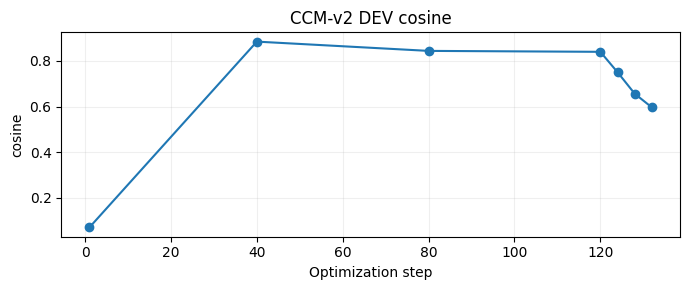

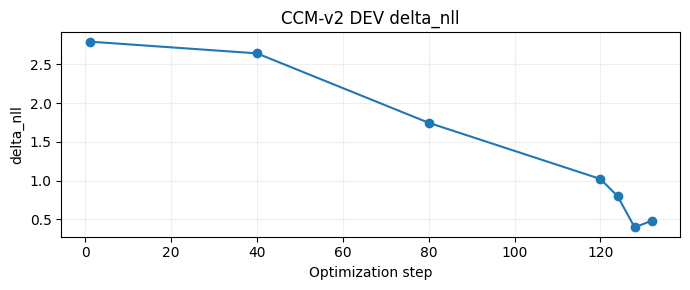

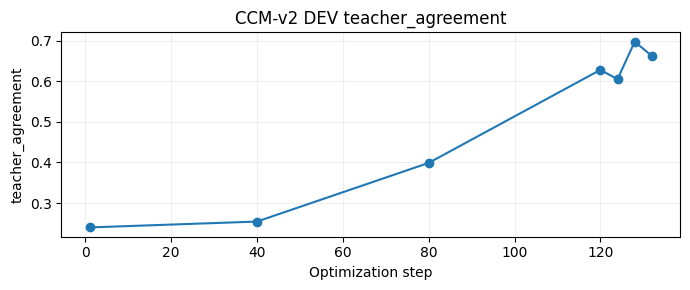

,metric,DEV,TEST
0,ΔNLL,0.395169,0.494939
1,Teacher prediction agreement,0.697507,0.657480
2,Native NLL,3.216881,3.595176
3,CCM NLL,3.612049,4.090115


NEGATIVE RESULT: Do NOT replace the deployed native first attention module.


In [5]:
#@title 5. Plot learning curves and show a machine-readable scorecard
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
frame=pd.read_csv(OUTPUT_DIR/'dev_history.csv')
display(frame[['step','phase','cosine','delta_nll','teacher_agreement','teacher_student_kl']])
for field in ['cosine','delta_nll','teacher_agreement']:
    plt.figure(figsize=(7,3))
    plt.plot(frame['step'],frame[field],marker='o')
    plt.xlabel('Optimization step');plt.ylabel(field);plt.grid(True,alpha=0.2)
    plt.title('CCM-v2 DEV '+field)
    plt.tight_layout();plt.savefig(OUTPUT_DIR/('dev_'+field+'.png'),dpi=140);plt.show()
score=pd.DataFrame([
 {'metric':'ΔNLL','DEV':report['dev']['delta_nll'],'TEST':report['test']['delta_nll']},
 {'metric':'Teacher prediction agreement','DEV':report['dev']['teacher_agreement'],'TEST':report['test']['teacher_agreement']},
 {'metric':'Native NLL','DEV':report['dev']['teacher_nll'],'TEST':report['test']['teacher_nll']},
 {'metric':'CCM NLL','DEV':report['dev']['student_nll'],'TEST':report['test']['student_nll']},
])
display(score)
if not report['accepted']:
    print('NEGATIVE RESULT: Do NOT replace the deployed native first attention module.')

In [6]:
#@title 6. Chat comparison table — identical prompts and greedy no-cache generation
chat=pd.read_json(OUTPUT_DIR/'chat_comparison.json')
if len(chat):
    simple=pd.DataFrame([{
      'case':c['case'],'prompt':c['prompt'],
      'original answer':c['teacher']['response'],
      'CCM answer':c['ccm']['response'],
      'exact match':c['exact_response_match']} for c in json.loads((OUTPUT_DIR/'chat_comparison.json').read_text())])
    display(simple)
else:print('No chat responses generated; check --skip-chat setting.')
print('Exact text agreement is diagnostic only, not a factual correctness score.')

,case,prompt,original answer,CCM answer,exact match
0,fact,What is the capital of Austria? Answer in one ...,The capital of Austria is Vienna.,The capital of Austria is Vienna.,True
1,arithmetic,What is 17 plus 25? Reply with the number only.,17 + 25 = 42,17 plus 25 is 42.,False
2,explanation,Explain the difference between RAM and SSD in ...,RAM (Random Access Memory) is the temporary st...,RAM is a type of memory that stores data tempo...,False
3,format,Respond with exactly three words about the Moon.,"Moon, Earth, Sun",The Moon is a celestial body.,False
4,recall,Remember this code: AURORA-731. What was the c...,The code you just gave me is:\n\n```\ndef get_...,The code you just gave me is a Python code sni...,False


Exact text agreement is diagnostic only, not a factual correctness score.


In [7]:
#@title 7. Optional custom chat prompt — edit text then rerun THIS cell
CUSTOM_PROMPT = ''  #@param {type:'string'}
if CUSTOM_PROMPT.strip():
    from scripts.benchmark_ccm_consensus_smol360 import chat_comparison
    custom=chat_comparison(session['model'],session['native'],session['adapter'],
         session['tokenizer'],[{'id':'custom','user':CUSTOM_PROMPT}],max_new_tokens=CHAT_MAX_NEW_TOKENS)
    (OUTPUT_DIR/'custom_chat.json').write_text(json.dumps(custom,indent=2))
else:
    print('Set CUSTOM_PROMPT to your question and rerun this cell to compare the original and CCM replies.')

Set CUSTOM_PROMPT to your question and rerun this cell to compare the original and CCM replies.


In [8]:
#@title 8. Package every result, training log, checkpoint and chat transcript; automatically download ZIP
import shutil
archive=shutil.make_archive(str(OUTPUT_DIR),'zip',root_dir=OUTPUT_DIR)
print('Generated:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Download the generated ZIP manually outside Google Colab')

Generated: /content/CCM_v2_360M_Consensus_Chat_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpreting the outcome

- **Pass:** measured DEV/test ΔNLL ≤ 0.02, prediction agreement ≥ 0.98, DEV local cosine ≥ 0.95, and full-model GPU speedup greater than 1.0×. These are screening acceptance gates, not evidence of scientific novelty.
- **Fail:** keep the native attention layer. The experiment saves its best **experimental** CCM checkpoint for diagnosis but never publishes a replacement model.
- **Chat tests:** native and candidate outputs are generated using the same prompt template, deterministic greedy choice and **full-prefix recomputation** without caching. They are qualitative sanity checks; a passing chat example does not imply full language-model parity.
- **Scope:** only `model.model.layers[0].self_attn` is replaced. The other attention layers are still native. CCM's mass consensus is mathematically softmax attention on a bounded memory tape, so the architecture is a stronger **upper-bound/feasibility control**, not proof of a novel attention-free algorithm.
- **Speed:** vectorized cellular prefill creates temporary `O(T × slots)` neighborhoods and is not a fused Triton kernel. It may be slower than native SDPA. Cached token-by-token generation and fully stand-alone model deployment require new implementations.
